In [10]:
import agama, numpy, matplotlib, matplotlib.pyplot as plt
from scipy import optimize 
from astropy import units as u 
from astropy import constants as cnst
# import hunter2024mwmodel as h2024
import barframe
plt.rcParams.update({
    "font.size": 11,
    "axes.labelsize": 11,
    "axes.titlesize": 11,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "text.usetex": True,
    "text.latex.preamble": r"\usepackage{txfonts}",
})


In [11]:
# omega= -37.5
# bar1    =   h2024.coleman2020(**h2024.coleman_components)
# bar2    =   h2024.portail_component(**h2024.portail_bar_1)
# bar3    =   h2024.portail_component(**h2024.portail_bar_2)    
# pbar1   =   agama.Potential(type='CylSpline', density=bar1,symmetry='triaxial',mmax=8,gridSizeR=40, gridSizeZ=40, Rmin=0.001, Rmax=20, Zmin=0.001, Zmax=20)
# pbar2   =   agama.Potential(type='CylSpline', density=bar2,symmetry='triaxial',mmax=8,gridSizeR=40, gridSizeZ=40, Rmin=0.001, Rmax=20, Zmin=0.001, Zmax=20)
# pbar3   =   agama.Potential(type='CylSpline', density=bar3,symmetry='triaxial',mmax=8,gridSizeR=40, gridSizeZ=40, Rmin=0.001, Rmax=20, Zmin=0.001, Zmax=20)
# pbar    =   pbar1+pbar2+pbar3

# # the rest of the potetial 
# psagA       =   agama.Potential(**h2024.supermassiveblackhole)
# pnsc        =   agama.Potential(**h2024.nsc)
# pnsd1       =   agama.Potential(**h2024.NSD1,)
# pnsd2       =   agama.Potential(**h2024.NSD2)
# pdisk1      =   agama.Potential(**h2024.DISK1)
# pdisk2      =   agama.Potential(**h2024.DISK2)
# pgdisk1     =   agama.Potential(**h2024.GDISK1)
# pgdisk2     =   agama.Potential(**h2024.GDISK2)
# phalo       =   agama.Potential(**h2024.EINASTO)
# pot_total   =   agama.Potential(pbar1,pbar2,pbar3,psagA,pnsc,pnsd1,pnsd2,pdisk1,pdisk2,pgdisk1,pgdisk2,phalo)
# pot_total_rotating = agama.Potential(potential=pot_total, rotation = [[0,0],[1,omega]])

In [12]:
def rotate(posvel, angle):
    x, y, z, vx, vy, vz = posvel.T
    sina, cosa = numpy.sin(angle), numpy.cos(angle)
    return numpy.array([x*cosa-y*sina, x*sina+y*cosa, z, vx*cosa-vy*sina, vx*sina+vy*cosa, vz]).T

NOTE. Try and put omega in the potential and integrate in the inertial frame for creating the library. 

In [13]:
# TRY A SIMPLER MODEL FIRST 
bartype = "Ferrers"
barmass = 1e10
barScaleRadius = 5.5
axisRatioY = 0.35
axisRatioZ = 0.25

type_d1 = "MiyamotoNagai"
mass_d1 = 6e10/barmass
scaleRadius_d1 = 3.5/barScaleRadius
scaleHeight_d1 = 0.28/barScaleRadius

type_d2 = "MiyamotoNagai"
mass_d2 = 1e10/barmass
scaleRadius_d2 = 2.0/barScaleRadius
scaleHeight_d2 = 0.8/barScaleRadius

type_halo = "NFW"
mass_halo = 1e12/barmass
scaleRadius_halo = 20.0/barScaleRadius

In [14]:
unitM = barmass*u.Msun
unitL = barScaleRadius*u.kpc 
oldUnitG = (u.km/u.s)**2 * (u.kpc/u.Msun)
G=cnst.G.to(oldUnitG)
unitV = (G*unitM/unitL)**(1/2)
agama.setUnits(length=unitL.value, mass=unitM.value, velocity=unitV.value)   # kpc, Msun, km/s
bar     = agama.Potential(type="Ferrers",mass=1,scaleRadius=1,axisRatioY=axisRatioY,axisRatioZ=axisRatioZ)
disk1   = agama.Potential(type=type_d1,mass=mass_d1,scaleRadius=scaleRadius_d1, scaleHeight=scaleHeight_d1)
disk2   = agama.Potential(type=type_d2,mass=mass_d2,scaleRadius=scaleRadius_d2, scaleHeight=scaleHeight_d2)
halo    = agama.Potential(type=type_halo,mass=mass_halo,scaleRadius=scaleRadius_halo, )
potential = bar + disk1 + disk2 + halo

In [15]:
unitRotation    =  unitV/unitL
omegaOld        = 37.5 * u.km / u.kpc / u.s
omegaNew        = omegaOld.to(unitRotation)
omega           = omegaNew.value
potential_rotating = agama.Potential(potential=potential, rotation = [[0,0], [1, omega]])

In [16]:
norbits     =   int(1e4)
ics,mass    =   bar.sample(norbits, potential=potential, beta=1/2,kappa=1/10)

In [17]:
xl1, EL1 = barframe.lagrange_l1_energy(potential, omega)
xzvc,yzvc = barframe.xy_plane_zero_velocity_curve(potential,omega,EL1)

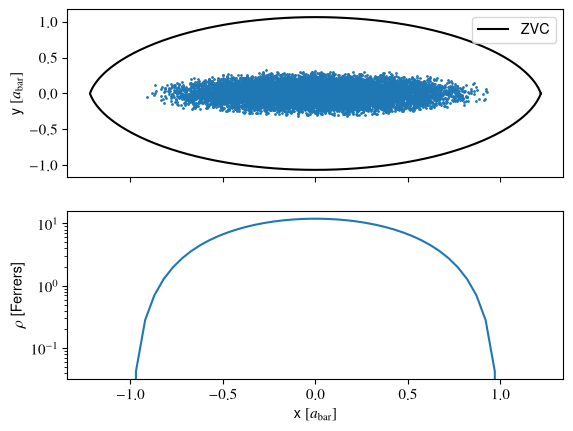

In [18]:
fig,axis=plt.subplots(2,1,sharex=True)
axis[0].scatter(ics[:,0],ics[:,1],s=1)
axis[0].plot(xzvc,yzvc,color="k",label="ZVC")
axis[0].set(ylabel=r"y $[a_{\mathrm{bar}}]$")
lgnd=axis[0].legend()
xs = numpy.linspace(-xl1,xl1)
pos = numpy.column_stack((xs,0*xs,0*xs))

axis[1].plot(numpy.linspace(-xl1,xl1), bar.density(pos));
axis[1].set(yscale="log",ylabel=r"$\rho$ [Ferrers]", xlabel=r"x $[a_{\mathrm{bar}}]$");

### Targets? 

1. First, just to the density naively, without regularisation with too few particles to see what happens 


**Questions**
- how do we get 704 bins for this binning scheme?

In [19]:
# DensityCylindricalLinear
stripsPerPane   =   2
gridr           =   agama.nonuniformGrid(11, 0.1, 1,)
target_density  =   agama.Target(type = "DensityClassicLinear",gridr = gridr, stripsPerPane = stripsPerPane, axisRatioY=axisRatioY, axisRatioZ=axisRatioZ)
times           =   50*potential.Tcirc(ics)

In [20]:
D,traj=agama.orbit(ic=ics,
                   potential=potential,
                   Omega=omega,
                   dtype=object,
                   time=times,
                   separateTime=True, 
                   targets=target_density)

10000 orbits complete (1261 orbits/s)


In [21]:
Lz = ics[:,0]*ics[:,4] - ics[:,1]*ics[:,3]
EJ = potential.potential(ics[:,:3]) + 0.5*numpy.sum(ics[:,3:]**2, axis=1) - omega*Lz
print((EJ > EL1).mean())

0.1347


In [22]:
# the bar mass
total_bar_mass = bar.totalMass()
# make each star the same mass
w = numpy.ones(norbits) * total_bar_mass / norbits
# get the discrete mass for each chunk
mass_discrete = D.T.dot(w)
mass_true = target_density(bar)

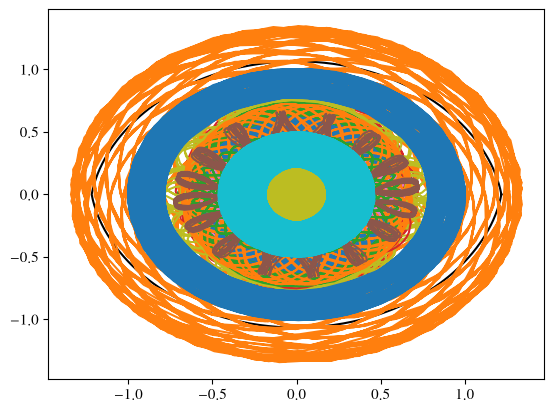

In [23]:
fig,axis=plt.subplots(1,1)
axis.plot(xzvc,yzvc,color="k",label="ZVC")
for index in range(100):
    axis.plot(traj[index](traj[index])[:,0],traj[index](traj[index])[:,1])

In [24]:
print((mass_true==0).sum(), )
print(len(mass_true))
print((D.sum(axis=0)==0).sum())

95
191
0


In [25]:
print(type(traj[index](traj[index])))
print(traj[index](traj[index]).shape)

<class 'numpy.ndarray'>
(1849, 6)


In [26]:
def r_ell(xv):
    return numpy.sqrt(xv[:,0]**2 + (xv[:,1]/axisRatioY)**2 + (xv[:,2]/axisRatioZ)**2)
i=2
t = numpy.linspace(traj[i][0], traj[i][-1], 2000)
print(r_ell(traj[i](t)).max())

2.0760519737281173


[Text(0, 0.5, 'discretized'), Text(0.5, 0, 'true mass'), None]

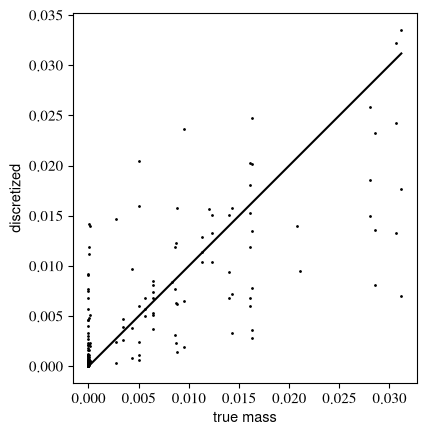

In [27]:
fig,axis = plt.subplots(1,1)
axis.scatter(mass_true,mass_discrete,s=1,color="k");
axis.plot([mass_true.min(), mass_true.max()],[mass_true.min(), mass_true.max()],zorder=10,color="k")
axis.set(ylabel="discretized", xlabel="true mass",aspect="equal")

In [28]:
data0 = numpy.ones((1, norbits))

try and make the constrain vector for the quadratic optimization 

In [29]:
constraints_density_uncertainty = 0.1 * mass_true

In [30]:
sigma   = numpy.maximum(0.1*mass_true, 0.05*mass_true.mean())
regul   = 1.0
weights = agama.solveOpt(
    matrix=[data0, D.T],
    rhs=[[total_bar_mass], mass_true],
    rpenq=[[numpy.inf], 2*sigma**-2],
    xpenq=2*numpy.ones(norbits)*norbits/total_bar_mass**2*regul)

Using a custom optimized KKT solver
numVariables=10191, numConstraints=192, numConsIneq=10000
Benchmarking BLAS backends for matrix size=(192,10191): cvxopt=0.002 s, numpy=0.002 s, scipy=0.003 s => choosing cvxopt
     pcost       dcost       gap    pres   dres
 0:  8.0646e+01  7.9641e+01  1e+04  1e+02  1e+02
 1:  8.0646e+01  7.9654e+01  2e+02  2e+00  2e+00
 2:  8.0646e+01  8.0086e+01  7e+01  7e-01  7e-01
 3:  8.2812e+01  8.0776e+01  7e+01  6e-01  6e-01
 4:  8.3411e+01  8.4402e+01  7e+01  4e-01  4e-01
 5:  8.4216e+01  8.9244e+01  6e+01  3e-01  3e-01
 6:  8.5774e+01  9.5949e+01  5e+01  2e-01  2e-01
 7:  8.7750e+01  1.0355e+02  5e+01  2e-01  2e-01
 8:  9.2781e+01  1.1850e+02  5e+01  1e-01  1e-01
 9:  9.8014e+01  1.3663e+02  5e+01  1e-01  1e-01
10:  1.0449e+02  1.5826e+02  5e+01  9e-02  9e-02
11:  1.1146e+02  1.8020e+02  5e+01  8e-02  8e-02
12:  1.1916e+02  2.0356e+02  6e+01  7e-02  7e-02
13:  1.3029e+02  2.3310e+02  7e+01  6e-02  6e-02
14:  1.4173e+02  2.6140e+02  7e+01  5e-02  5e-02
15:

total mass: 1.0000000009628398 target: 1.0000000000000064
chi2/ncells: 6.171828637307169
cells off by > 1 sigma: 62 of 191


[Text(0.5, 0, '(model - true)/$\\sigma$')]

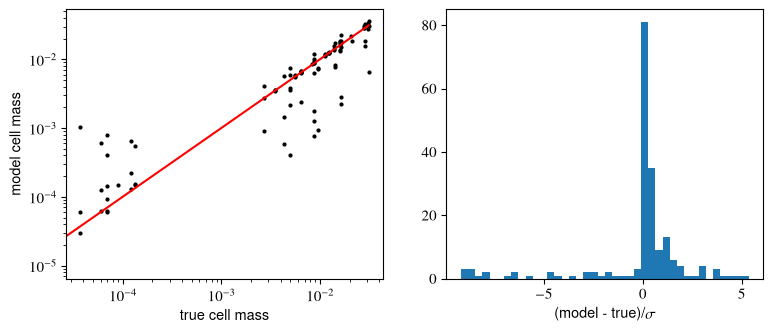

In [31]:
mass_model = D.T.dot(weights)
rel = (mass_model - mass_true) / sigma          # in units of the tolerance
print("total mass:", weights.sum(), "target:", total_bar_mass)
print("chi2/ncells:", numpy.mean(rel**2))
print("cells off by > 1 sigma:", (abs(rel) > 1).sum(), "of", len(rel))

fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
ax[0].scatter(mass_true, mass_model, s=4, c="k")
ax[0].plot([mass_true.min(), mass_true.max()], [mass_true.min(), mass_true.max()], "r")
ax[0].set(xscale="log", yscale="log", xlabel="true cell mass", ylabel="model cell mass")
ax[1].hist(rel, bins=40); ax[1].set(xlabel=r"(model - true)/$\sigma$")

In [32]:

def analyze_weights(weights):
    n = len(weights)
    nw = weights * n / weights.sum()
    print("max weight (closer to 1 = better): %.3g" % nw.max())
    print("mean square weight (closer to 1 = better): %.3g" % numpy.mean(nw**2))
    print("orbits carrying 90%% of mass: %i / %i" %
          (numpy.searchsorted(numpy.cumsum(numpy.sort(weights)[::-1]), 0.9*weights.sum()), n))
    print("orbits with weight < 1e-3 of mean: %i" % (nw < 1e-3).sum())
analyze_weights(weights)

max weight (closer to 1 = better): 215
mean square weight (closer to 1 = better): 66
orbits carrying 90% of mass: 204 / 10000
orbits with weight < 1e-3 of mean: 9666


[Text(0.5, 0, 'initial elliptical radius'), None]

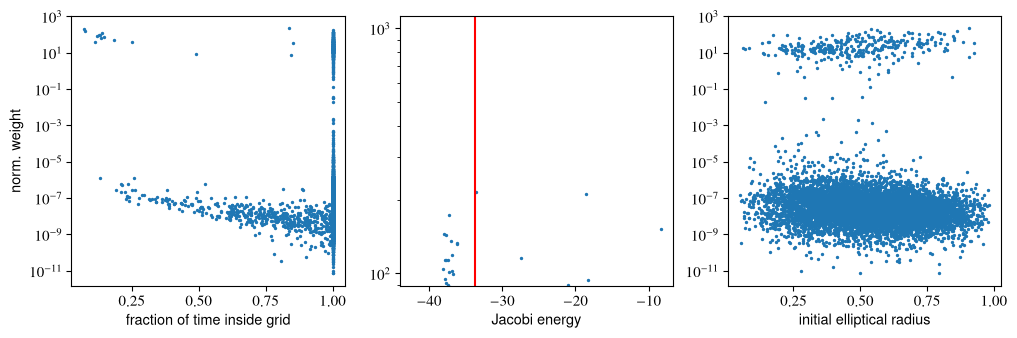

In [33]:
frac_inside = D.sum(axis=1)
nw = weights * norbits / weights.sum()
fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))
ax[0].scatter(frac_inside, nw, s=2); ax[0].set(xlabel="fraction of time inside grid", ylabel="norm. weight", yscale="log")
ax[1].scatter(EJ, nw, s=2); ax[1].axvline(EL1, c="r"); ax[1].set(xlabel="Jacobi energy", yscale="log")
r0 = numpy.sqrt(ics[:,0]**2 + (ics[:,1]/axisRatioY)**2 + (ics[:,2]/axisRatioZ)**2)
ax[2].scatter(r0, nw, s=2); ax[2].set(xlabel="initial elliptical radius", yscale="log")

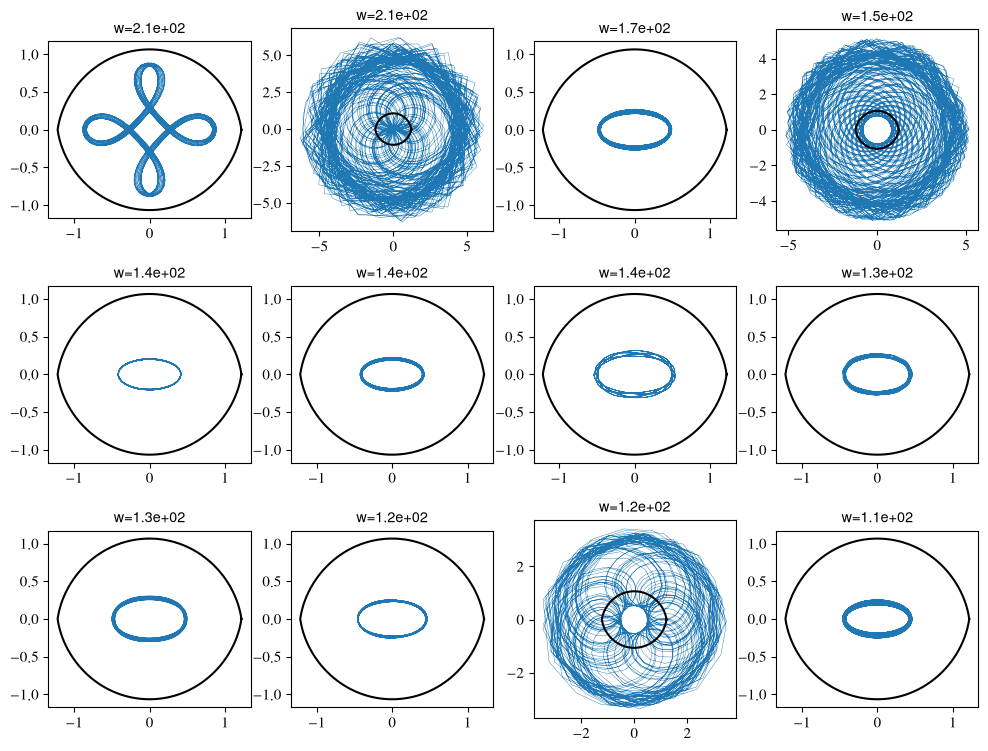

In [34]:
top = numpy.argsort(weights)[::-1][:12]
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for a, i in zip(axes.flat, top):
    xv = traj[i](traj[i])
    a.plot(xv[:,0], xv[:,1], lw=0.3); a.set(aspect="equal", title="w=%.2g" % nw[i])
    a.plot(xzvc,yzvc,color="k")

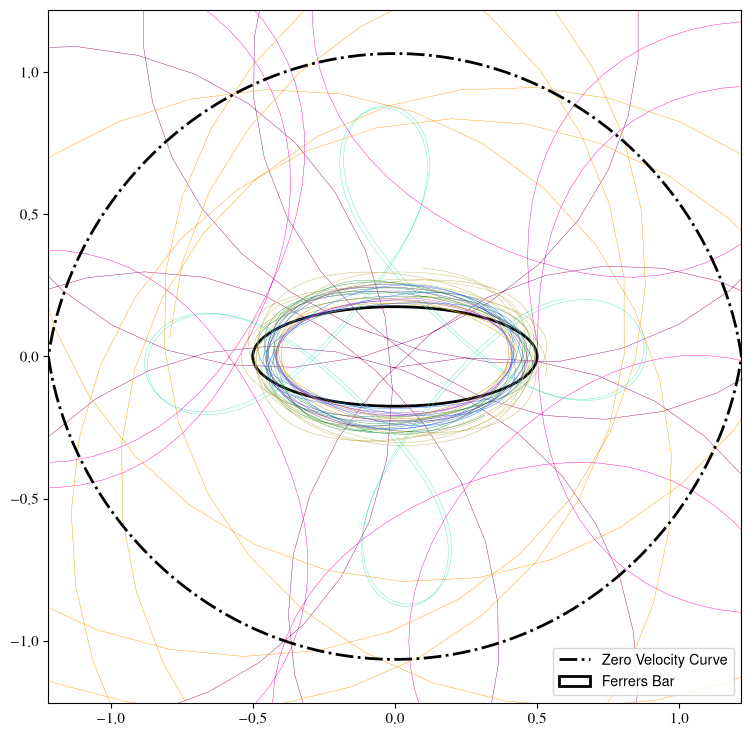

In [35]:
top = numpy.argsort(weights)[::-1][:12]
ferrersbar=matplotlib.patches.Ellipse((0,0),width=1,height=axisRatioY,facecolor=None,edgecolor="k",fill=False,linewidth=2,linestyle="-",label="Ferrers Bar")
fig, axes = plt.subplots(1,1, figsize=(12, 9))
for i in top:
    color = numpy.random.rand(3)
    # xv = traj[i](traj[i])
    xv = traj[i](numpy.linspace(0,times[i]/10,int(1e3)))
    axes.plot(xv[:,0], xv[:,1], lw=0.3,c=color); 
    a.set(aspect="equal", title="w=%.2g" % nw[i])
axes.plot(xzvc,yzvc,color="k",linewidth=2,linestyle="-.",label="Zero Velocity Curve")
axes.add_patch(ferrersbar)
axes.set(xlim=[-xl1,xl1],ylim=[-xl1,xl1],aspect="equal")
axes.legend()

### Examine the model

NOTE. I have to be smarted with the virial theorem in this case. More careful than was presented in the tutorial because it contained the n-body particles as well as a black hole. So, the black hole needed to be considered seperately. Here, I have external forces on the particles. They must be counted as well. Here is how the virial theorem should look: 

First, consider the moment of inertial of this system: 

$$ I = \sum_i m_i \mathbf{r}_i^2$$

Why is this the best starting point with the virial theorem? because, if $I>0$ then our system is expanding. If $I<0$ then our system is contract. We want a system that, on average, is steady. So, it can expand and contract momentarily, but on average, they cancel. Thus, the time average of the second derivative is zero: 

$$ \langle \ddot{I} \rangle = 0 $$

So, let's compute this. 

$$\frac{d}{dt} I = \sum_i 2m_i \mathbf{r}_i\cdot\dot{\mathbf{r}}_i$$

$$\frac{d}{dt} \dot{I} = \sum_i 2m_i \left( \dot{\mathbf{r}}_i\cdot \dot{\mathbf{r}}_i +   \mathbf{r}_i\cdot\ddot{\mathbf{r}}_i\right)$$
Move the 1/2 out to be more elegant

$$\frac{1}{2} \ddot{I} = \sum_i m_i \dot{\mathbf{r}}_i\cdot \dot{\mathbf{r}}_i  + \sum_i m_i   \mathbf{r}_i\cdot\ddot{\mathbf{r}}_i$$

#### The Kinetic energy term 

First, we can throw in the total kinetic energy of the system

$$ 2K = \sum_i m_i \dot{\mathbf{r}}_i\cdot \dot{\mathbf{r}}_i $$

And, we can move the mass to then get the force acting on the particle: $\mathbf{r}_i\cdot m_i\mathbf{\ddot{r}}_i$

$$\frac{1}{2} \ddot{I} = 2K + \sum_i \mathbf{r}_i\cdot\mathbf{F}_i$$

Now comes a tricky part. The forces, in my cases, is going to be n-body forces, as well as forces from the external field! $\mathbf{F}_i = \mathbf{F}^{\mathrm{int}}_i + \mathbf{F}^{\mathrm{ext}}_i$

#### The internal energy

First, i'll consider the nbody forces, which are the intenral ones:
$$\mathbf{F}^{\mathrm{int}}_i=Gm_i m_j\frac{\left(\mathbf{r}_j-\mathbf{r}_i\right)} {|\mathbf{r}_i - \mathbf{r}_j|^3} $$

Note that I don't like the minus sign. So, I like to to think about the final position minus the initial position. On the $i^{\mathrm{th}}$ particle, the force points to the $j^{\mathrm{th}}$

$$\sum_i \mathbf{r}_i\cdot\mathbf{F}_i = \sum_i\sum_{j\neq i}Gm_i m_j\frac{\mathbf{r}_i\cdot\left(\mathbf{r}_j-\mathbf{r}_i\right)} {|\mathbf{r}_i - \mathbf{r}_j|^3} $$


This is where summation and indexing logic always blows my mind. You have to be creative here. Instead of thinking of many algebratic terms, we can just think of this as a 2D matrix.

$$S = \sum_i^N \sum_{j\neq i}^N A_{ij}$$

So, we're summing over all the elements besides the diagonal. And, this sum is $S$. 

Here, in my mind, we're going to "fold" the matrix about the diagonal. Instead of summing over all the elements, we can sum over a traingular portion, but count each pair twice. 

$$S = \sum_i^N \sum_{j< i} \left(A_{ij} + A_{ji}\right)$$

This is going to allow us to greatly simplify the problem, because, we can take advantage of basic vector addition to simplify our expression for the matrix elements

$$ A_{ij} + A_{ji} = Gm_i m_j\left(\frac{\mathbf{r}_i\cdot\left(\mathbf{r}_j-\mathbf{r}_i\right)}{\left|\mathbf{r}_j-\mathbf{r}_i\right|^3 } + \frac{\mathbf{r}_j\cdot\left(\mathbf{r}_i-\mathbf{r}_j\right)}{\left|\mathbf{r}_i-\mathbf{r}_j\right|^3 } \right)$$

The norms is associative: $\left|\mathbf{r}_i-\mathbf{r}_j\right| = \left|\mathbf{r}_j-\mathbf{r}_i\right|$

Vector subtraction changes the sign: $\mathbf{r}_j-\mathbf{r}_i=-\left( \mathbf{r}_i-\mathbf{r}_j \right)$

And with some factoring, you get: 

$$A_{ij} + A_{ji} = Gm_i m_j\frac{(\mathbf{r}_j - \mathbf{r}_i)\cdot(\mathbf{r}_i - \mathbf{r}_j)}{|\mathbf{r}_i - \mathbf{r}_j|^3}$$

and once again, flip the sign: 

$$A_{ij} + A_{ji} = -G\frac{m_i m_j}{|\mathbf{r}_i - \mathbf{r}_j|}$$

So now, this sum, is the self gravity. 

$$S=W_{\mathrm{self}}=\sum_i^N\sum_{j<i}-G\frac{m_i m_j}{|\mathbf{r}_i - \mathbf{r}_j|}$$

But, note that in Agama, we don't do the double sum. We do a multi-pole expansion for the internal potential. It would be this: 

$$\alpha = \sum_i^N m_i \Phi_{\mathrm{self}}(r_i)$$

But, now we must construct the $\Phi_{\mathrm{self}}$, which is of course:

$$\Phi_{\mathrm{self}}(\mathbf{r}_i) = -\sum_{j\neq i}\frac{Gm_j}{|\mathbf{r}_i-\mathbf{r}_j|}$$

How does this relate to the total internal energy? we cna sub back in: 

$$\alpha = -G\sum_i^N \sum_{j\neq i}^{N}\frac{m_i m_j}{|\mathbf{r}_i-\mathbf{r}_j|}$$

And, note that this is doulbe counting! it's summing over both halves of the matrix. So,

$$\alpha = 2 W_{\mathrm{int}}$$

TL;DR, if we're using a multi-pole expansion for the internal field, then, it should be: 

$$W_{\mathrm{int}} = \frac{1}{2}\sum_i m_i\Phi(\mathbf{r}_i)$$


#### The external energy 

$$\mathbf{F}_{i}^{\mathrm{ext}} = m_i\nabla\Phi(\mathbf{r_i})$$

And really, that's it. We can't simplify it further: 

$$W_{\mathrm{ext}} = \sum_i^N \mathbf{r}_i\cdot m_i\nabla\Phi(r_i)$$



In [36]:
Nbody = 100000
snap_posvel, snap_mass = agama.sampleOrbitLibrary(Nbody, traj, weights)

In [37]:
# approximate the potential with a multipole expansion 
pot_stars_nbody =   agama.Potential(type='multipole', particles=(snap_posvel, snap_mass), symmetry='t')
# add the potential from the other componenets
prest       =   disk1 + disk2 + halo
E_pot_nbbdy =   0.5 * numpy.sum(snap_mass * pot_stars_nbody.potential(snap_posvel[:,0:3])) 
E_pot_rest  =   0.5 * numpy.sum(snap_mass * prest.potential(snap_posvel[:,0:3]))
E_kin       =   0.5 * numpy.sum(snap_mass[:,None] * snap_posvel[:,3:6]**2)
virial_ratio = -2 * E_kin / (E_pot_rest+E_pot_nbbdy)
print(virial_ratio)

0.2369902833487604


In [38]:
pos  = snap_posvel[:,0:3]
W_self = 0.5*numpy.sum(snap_mass * pot_stars_nbody.potential(pos))
force_rest = prest.force(pos)                      # -∇Φ_rest, shape (N,3)
W_ext  = numpy.sum(snap_mass * numpy.sum(pos*force_rest, axis=1))
# the N-body self-force virial equals W_self for 1/r potentials
virial_ratio = -2*E_kin / (W_self + W_ext)
print(virial_ratio)

0.958799828753951


In [39]:
import pyfalcon 

In [40]:
mass

array([0.00010011, 0.00010011, 0.00010011, ..., 0.00010011, 0.00010011,
       0.00010011], shape=(10000,))

In [ ]:
eps = 1e-3 * u.kpc
eps = eps.to(unitL).value

np.float64(0.00018181818181818183)

In [ ]:
accelerations, potential =  pyfalcon.gravity(snap_posvel[:,0:3], snap_mass, eps=eps)

(100000, 3)